# CASTORS Research Initiative — Observed-Outcome Decision Tree

**Question:** How accurately can unemployment, households without vehicles, and SNAP retailer proximity estimate *observed SNAP participation across held-out Trumbull County Census tracts*?

This is a **cross-sectional regression tree**. SNAP participation is an observed program-use measure, **not food insecurity, food waste, or future demand**. The 2020-derived SRAM SNAP/household variables and 2020–2024 ACS unemployment cover different periods. Do **not** interpret this as forecasting 2026 food needs.

Your desired order (unemployment → vehicle access → retailer distance) is a *policy rule hierarchy*. A statistically trained tree must be free to select splits based on predictive fit; the model may not follow that order.

In [ ]:
from google.colab import files
import io
import pandas as pd, numpy as np
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

uploaded = files.upload()
filename = next((k for k in uploaded if k.endswith("CASTORS_Trumbull_Master_Python.csv")), None)
if filename is None:
    raise ValueError("Upload CASTORS_Trumbull_Master_Python.csv. You uploaded: " + ", ".join(uploaded.keys()))
df = pd.read_csv(io.BytesIO(uploaded[filename]), dtype={"GEOID": str})
assert df.GEOID.str.len().eq(11).all() and df.GEOID.is_unique
print("Tracts:", len(df))

Saving CASTORS_Trumbull_Master_Python.csv to CASTORS_Trumbull_Master_Python.csv
Tracts: 54


## Define predictors and an independently observed outcome

We use the **household SNAP participation share** as the target, rather than the earlier invented High/Moderate/Low categories. Do not include `SRAM_TractSNAP`, the outcome itself, as a predictor. Counts are normalized by occupied households, allowing tracts of different sizes to be compared.

The predictor list is ordered for presentation only; scikit-learn may choose any variable at each split.

In [ ]:
X = pd.DataFrame({
    "Unemployment_Rate_Pct": pd.to_numeric(df["ACS_Unemployment_Rate_Pct"]),
    "No_Vehicle_Households_Pct": 100 * pd.to_numeric(df["SRAM_TractHUNV"]) / pd.to_numeric(df["SRAM_OHU2020"]),
    "Beyond_1_Mile_Driving_Pct": pd.to_numeric(df["SRAM_DD_SRAM_lapop1share"]),
})
y = 100 * pd.to_numeric(df["SRAM_TractSNAP"]) / pd.to_numeric(df["SRAM_OHU2020"])
assert np.isfinite(X.to_numpy()).all() and np.isfinite(y.to_numpy()).all()
assert X.apply(lambda s: s.between(0, 100)).all().all() and y.between(0, 100).all()
print(X.describe().round(2))
print("\nObserved SNAP participation summary:\n", y.describe().round(2))

       Unemployment_Rate_Pct  No_Vehicle_Households_Pct  \
count                  54.00                      54.00   
mean                    4.88                       8.50   
std                     3.24                       9.11   
min                     0.49                       0.00   
25%                     2.59                       3.66   
50%                     4.22                       6.45   
75%                     6.63                       9.01   
max                    14.97                      51.12   

       Beyond_1_Mile_Driving_Pct  
count                      54.00  
mean                       44.11  
std                        34.87  
min                         0.00  
25%                        12.98  
50%                        44.18  
75%                        78.02  
max                       100.00  

Observed SNAP participation summary:
 count    54.00
mean     15.31
std      12.84
min       0.99
25%       6.99
50%      11.48
75%      20.02
max      

## Honest validation on held-out tracts

We use five folds (not a random train/test split with only about 11 test tracts). **Every prediction is made by a model that did not train on that tract**. We also compare against a simple baseline using the *training-fold average*. Hyperparameters are fixed in advance, rather than selected using the test folds.

Because nearby tracts may resemble each other, **spatial-block validation** is still needed before claiming broader geographic generalization. Fifty-four tracts is a small sample and ACS estimates have uncertainty.

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
oof = np.full(len(y), np.nan); baseline = np.full(len(y), np.nan); fold = np.empty(len(y), dtype=int)
for i, (train_idx, test_idx) in enumerate(cv.split(X), start=1):
    tree = DecisionTreeRegressor(max_depth=2, min_samples_leaf=8, random_state=42)
    tree.fit(X.iloc[train_idx], y.iloc[train_idx])
    oof[test_idx] = tree.predict(X.iloc[test_idx])
    baseline[test_idx] = y.iloc[train_idx].mean()
    fold[test_idx] = i
print(f"Tree MAE: {mean_absolute_error(y, oof):.2f} percentage points")
print(f"Training-fold mean baseline MAE: {mean_absolute_error(y, baseline):.2f} percentage points")
print(f"Tree cross-validated R²: {r2_score(y, oof):.3f}")
print("Interpret performance before proceeding. Low or negative R² means not a robust predictive model.")

Tree MAE: 8.53 percentage points
Training-fold mean baseline MAE: 9.19 percentage points
Tree cross-validated R²: 0.058
Interpret performance before proceeding. Low or negative R² means not a robust predictive model.


## Visualize and interpret the trained tree

The diagram below is the final fitted model for interpretation. **Do not use its in-sample fitted values to claim model accuracy**; only the held-out predictions above assess that.

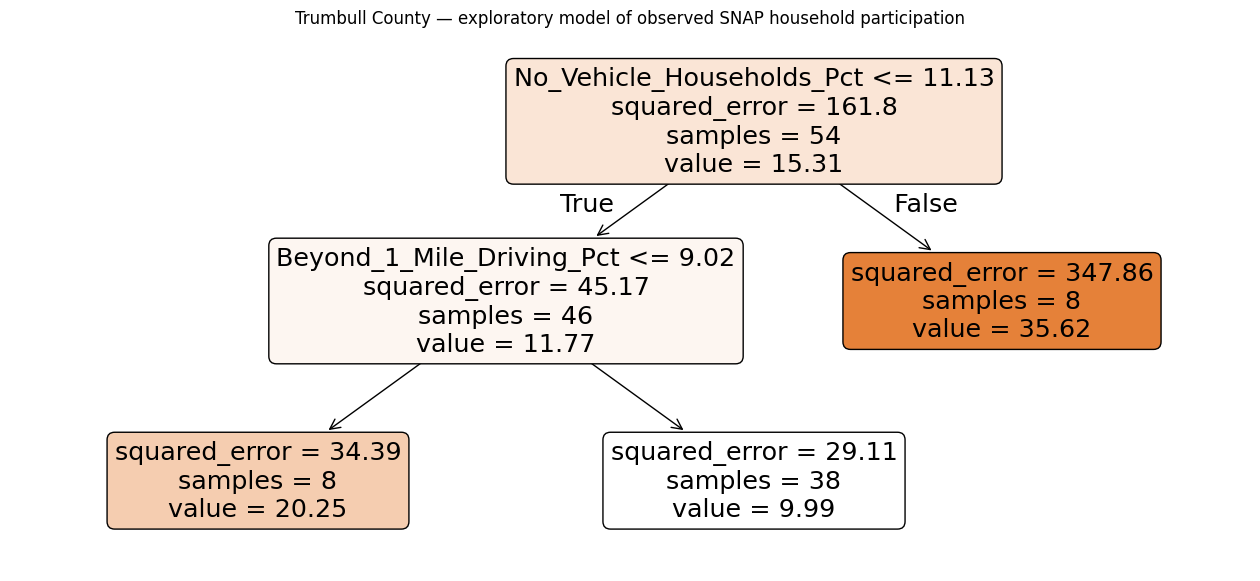

No_Vehicle_Households_Pct    0.847692
Beyond_1_Mile_Driving_Pct    0.152308
Unemployment_Rate_Pct        0.000000
dtype: float64


In [ ]:
final_tree = DecisionTreeRegressor(max_depth=2, min_samples_leaf=8, random_state=42).fit(X, y)
plt.figure(figsize=(16, 7))
plot_tree(final_tree, feature_names=list(X.columns), filled=True, rounded=True, precision=2)
plt.title("Trumbull County — exploratory model of observed SNAP household participation")
plt.show()
print(pd.Series(final_tree.feature_importances_, index=X.columns).sort_values(ascending=False))

Upload your validated Decision Tree results CSV.


Saving CASTORS_Predictive_Tree_Validated_Results(1).csv to CASTORS_Predictive_Tree_Validated_Results(1).csv

Census tracts analyzed: 54

1. DOES IT WORK?

Overall predictive performance:
                  MAE     RMSE      R2
Decision Tree  8.5289  12.3468  0.0579
Baseline       9.1877  12.8069 -0.0137

MAE improvement over baseline: 7.17%

Performance across validation folds:
   Fold  Number_of_Tracts     MAE    RMSE
0     1                11  10.005  13.014
1     2                11   7.442   9.548
2     3                11   3.443   5.008
3     4                11  11.463  14.472
4     5                10  10.469  16.692


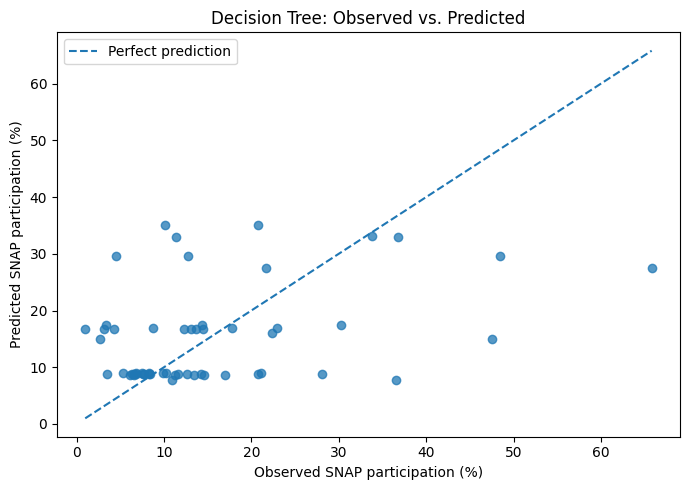


2. IS IT TRUSTWORTHY?

Error analysis:
Mean signed error: -0.073
Underpredicted tracts: 23
Overpredicted tracts: 31
Tracts with errors greater than 10 points: 18

Ten largest prediction errors:


,GEOID,Tract_Name,Observed_SNAP_Household_Share_Pct,CV_Predicted_SNAP_Share_Pct,Prediction_Error,Absolute_Error
51,39155933800,"Census Tract 9338, Trumbull County, Ohio",65.813,27.416,-38.397,38.397
53,39155934000,"Census Tract 9340, Trumbull County, Ohio",47.560,14.957,-32.603,32.603
2,39155920700,"Census Tract 9207, Trumbull County, Ohio",36.606,7.737,-28.869,28.869
17,39155930500,"Census Tract 9305, Trumbull County, Ohio",4.471,29.602,25.131,25.131
39,39155932801,"Census Tract 9328.01, Trumbull County, Ohio",10.071,35.118,25.047,25.047
37,39155932701,"Census Tract 9327.01, Trumbull County, Ohio",11.400,33.011,21.611,21.611
52,39155933900,"Census Tract 9339, Trumbull County, Ohio",28.141,8.800,-19.341,19.341
3,39155920800,"Census Tract 9208, Trumbull County, Ohio",48.511,29.602,-18.909,18.909
49,39155933600,"Census Tract 9336, Trumbull County, Ohio",12.786,29.602,16.816,16.816
43,39155933002,"Census Tract 9330.02, Trumbull County, Ohio",0.988,16.687,15.699,15.699


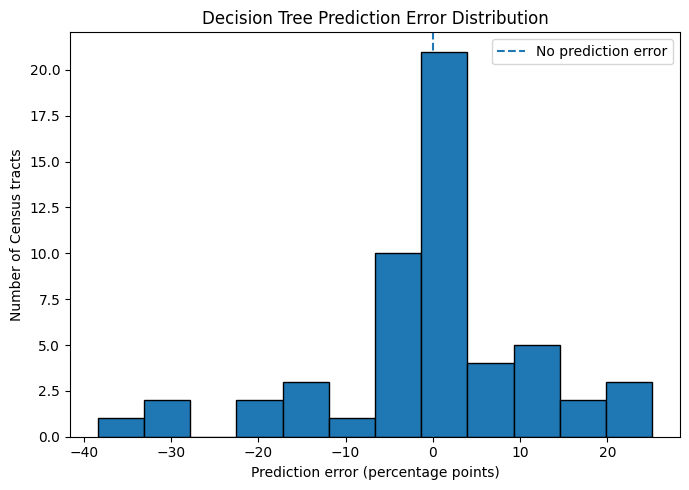


Subgroup error comparison:
                                Number_of_Tracts     MAE  Mean_Signed_Error
Vehicle_Access_Group                                                       
Higher transportation barriers                27  10.903             -1.946
Lower transportation barriers                 27   6.155              1.800

3. IS IT OPERATIONALLY USEFUL?

Total Census tracts: 54
Tracts selected for analyst review: 11
Correctly identified high-participation tracts: 5
Recall at 11: 0.455
Expected recall from random selection: 0.204

Predictions within ±10 percentage points: 66.7%

Evaluation complete. Downloading results.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# CASTORS RESEARCH INITIATIVE
# ORIGINAL DECISION TREE MODEL EVALUATION
#
# 1. DOES IT WORK?
# 2. IS IT TRUSTWORTHY?
# 3. IS IT OPERATIONALLY USEFUL?
#
# Evaluates existing out-of-fold predictions.
# Does NOT retrain or tune the Decision Tree.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1: UPLOAD YOUR ORIGINAL RESULTS
# ------------------------------------------------------------

print("Upload your validated Decision Tree results CSV.")
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

target = "Observed_SNAP_Household_Share_Pct"
prediction = "CV_Predicted_SNAP_Share_Pct"
baseline = "CV_Baseline_SNAP_Share_Pct"
fold = "CV_Fold"

required = [target, prediction, baseline, fold]

missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df.dropna(subset=required).copy()

actual = df[target].to_numpy()
predicted = df[prediction].to_numpy()
baseline_pred = df[baseline].to_numpy()

print(f"\nCensus tracts analyzed: {len(df)}")


# ============================================================
# TEST 1: DOES IT WORK?
# ============================================================

def evaluate(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted)
    }

results = pd.DataFrame({
    "Decision Tree": evaluate(actual, predicted),
    "Baseline": evaluate(actual, baseline_pred)
}).T

print("\n1. DOES IT WORK?")
print("\nOverall predictive performance:")
print(results.round(4))

# Percentage improvement over baseline MAE
tree_mae = results.loc["Decision Tree", "MAE"]
base_mae = results.loc["Baseline", "MAE"]

improvement = (
    (base_mae - tree_mae) / base_mae
) * 100

print(f"\nMAE improvement over baseline: {improvement:.2f}%")

# Performance across the original validation folds
fold_results = []

for fold_number, group in df.groupby(fold):

    metrics = evaluate(
        group[target],
        group[prediction]
    )

    fold_results.append({
        "Fold": fold_number,
        "Number_of_Tracts": len(group),
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"]
    })

fold_table = pd.DataFrame(fold_results)

print("\nPerformance across validation folds:")
print(fold_table.round(3))

# Actual vs predicted chart
plt.figure(figsize=(7, 5))

plt.scatter(
    actual,
    predicted,
    alpha=0.75
)

limits = [
    min(actual.min(), predicted.min()),
    max(actual.max(), predicted.max())
]

plt.plot(
    limits,
    limits,
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Observed SNAP participation (%)")
plt.ylabel("Predicted SNAP participation (%)")
plt.title("Decision Tree: Observed vs. Predicted")
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# TEST 2: IS IT TRUSTWORTHY?
# ============================================================

# Signed error:
# Negative = model underpredicts
# Positive = model overpredicts

df["Prediction_Error"] = (
    df[prediction] - df[target]
)

df["Absolute_Error"] = abs(
    df["Prediction_Error"]
)

print("\n2. IS IT TRUSTWORTHY?")

print("\nError analysis:")

print(
    "Mean signed error:",
    round(df["Prediction_Error"].mean(), 3)
)

print(
    "Underpredicted tracts:",
    int((df["Prediction_Error"] < 0).sum())
)

print(
    "Overpredicted tracts:",
    int((df["Prediction_Error"] > 0).sum())
)

print(
    "Tracts with errors greater than 10 points:",
    int((df["Absolute_Error"] > 10).sum())
)

# Show the ten largest prediction errors
print("\nTen largest prediction errors:")

display_columns = [
    col for col in ["GEOID", "Tract_Name"]
    if col in df.columns
]

display_columns += [
    target,
    prediction,
    "Prediction_Error",
    "Absolute_Error"
]

display(
    df.nlargest(
        10,
        "Absolute_Error"
    )[display_columns]
)

# Error distribution
plt.figure(figsize=(7, 5))

plt.hist(
    df["Prediction_Error"],
    bins=12,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    label="No prediction error"
)

plt.xlabel("Prediction error (percentage points)")
plt.ylabel("Number of Census tracts")
plt.title("Decision Tree Prediction Error Distribution")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# FAIRNESS / SUBGROUP ERROR ASSESSMENT
# ------------------------------------------------------------

# Compare errors across higher vs lower
# transportation-barrier tracts.

vehicle_col = "No_Vehicle_Households_Pct"

if vehicle_col in df.columns:

    median_vehicle = df[vehicle_col].median()

    df["Vehicle_Access_Group"] = np.where(
        df[vehicle_col] >= median_vehicle,
        "Higher transportation barriers",
        "Lower transportation barriers"
    )

    fairness = df.groupby(
        "Vehicle_Access_Group"
    ).agg(
        Number_of_Tracts=(target, "size"),
        MAE=("Absolute_Error", "mean"),
        Mean_Signed_Error=("Prediction_Error", "mean")
    )

    print("\nSubgroup error comparison:")
    print(fairness.round(3))

else:
    print(
        "\nVehicle access variable not available."
    )
    print(
        "Join the master dataset to conduct this assessment."
    )


# ============================================================
# TEST 3: IS IT OPERATIONALLY USEFUL?
# ============================================================

print("\n3. IS IT OPERATIONALLY USEFUL?")

# Demonstration:
# Suppose an analyst can review 20% of Census tracts.
#
# How many of the tracts with the highest OBSERVED SNAP
# participation would be selected using model predictions?

review_fraction = 0.20

k = max(
    1,
    int(np.ceil(len(df) * review_fraction))
)

actual_top = set(
    np.argsort(-actual)[:k]
)

predicted_top = set(
    np.argsort(-predicted)[:k]
)

correctly_identified = len(
    actual_top.intersection(predicted_top)
)

recall_at_k = correctly_identified / k

print(f"\nTotal Census tracts: {len(df)}")
print(f"Tracts selected for analyst review: {k}")
print(f"Correctly identified high-participation tracts: "
      f"{correctly_identified}")
print(f"Recall at {k}: {recall_at_k:.3f}")

# Compare model prioritization to random selection
random_expected = k / len(df)

print(
    "Expected recall from random selection:",
    round(random_expected, 3)
)

# A hypothetical operational review threshold
# This is not a validated threshold for community need.

threshold = 10

within_threshold = (
    df["Absolute_Error"] <= threshold
).mean() * 100

print(
    f"\nPredictions within ±{threshold} percentage points:",
    f"{within_threshold:.1f}%"
)


# ============================================================
# EXPORT RESULTS
# ============================================================

df.to_csv(
    "CASTORS_Decision_Tree_Evaluation.csv",
    index=False
)

results.to_csv(
    "CASTORS_Decision_Tree_Performance.csv"
)

fold_table.to_csv(
    "CASTORS_Decision_Tree_Fold_Results.csv",
    index=False
)

print("\nEvaluation complete. Downloading results.")

files.download("CASTORS_Decision_Tree_Evaluation.csv")
files.download("CASTORS_Decision_Tree_Performance.csv")
files.download("CASTORS_Decision_Tree_Fold_Results.csv")


Upload CASTORS_Predictive_Tree_Validated_Results.csv


Saving CASTORS_Predictive_Tree_Validated_Results(1).csv to CASTORS_Predictive_Tree_Validated_Results(1) (1).csv

Census tracts: 54
Cross-validation folds: 5

1. DOES IT WORK?

Model performance comparison:
                  MAE     RMSE      R2
Decision Tree  8.5289  12.3468  0.0579
Random Forest  6.9816  10.2317  0.3530
Baseline       9.1877  12.8069 -0.0137

Random Forest MAE improvement vs. tree: 18.14%

Cross-validation fold comparison:
   Fold  Number_of_Tracts  Random_Forest_MAE  Decision_Tree_MAE
0     1                11              7.439             10.005
1     2                11              6.059              7.442
2     3                11              4.239              3.443
3     4                11              7.976             11.463
4     5                10              9.417             10.469


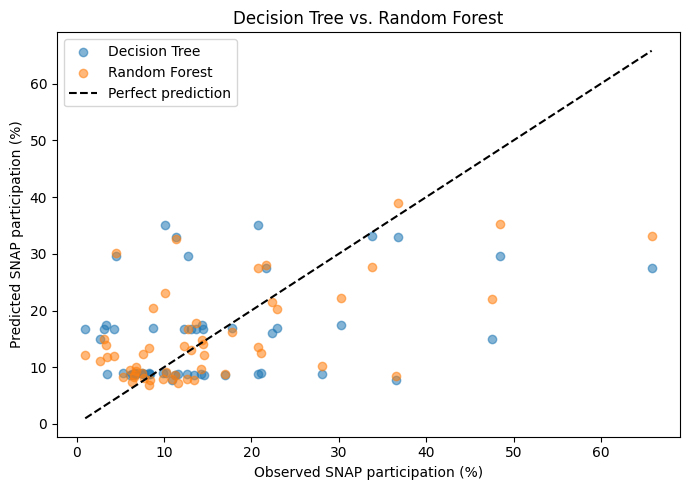


2. IS IT TRUSTWORTHY?

Decision Tree
Mean signed error: -0.073
Underpredicted tracts: 23
Errors greater than 10 points: 18

Random Forest
Mean signed error: -0.201
Underpredicted tracts: 26
Errors greater than 10 points: 12

Subgroup error comparison:
                                Number_of_Tracts  Tree_MAE  Random_Forest_MAE  \
Vehicle_Access_Group                                                            
Higher transportation barriers                27    10.903              8.898   
Lower transportation barriers                 27     6.155              5.065   

                                Tree_Signed_Error  RF_Signed_Error  
Vehicle_Access_Group                                                
Higher transportation barriers             -1.946           -1.111  
Lower transportation barriers               1.800            0.710  


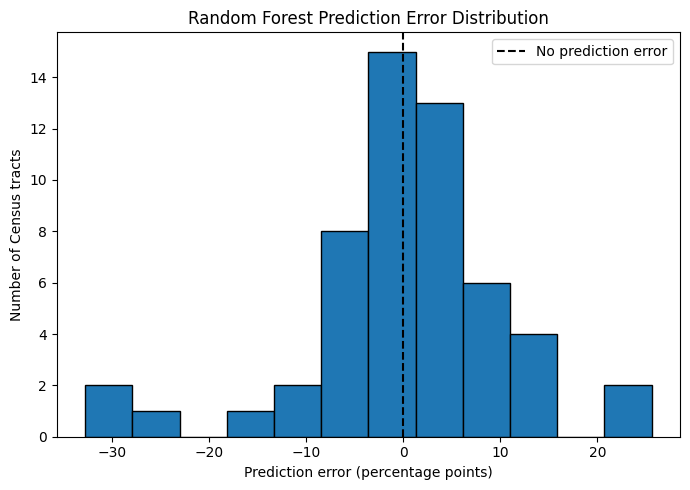


3. IS IT OPERATIONALLY USEFUL?

Operational comparison:
        Model  Tracts_Reviewed  Correctly_Identified  Recall_at_K  Lift_at_K  Within_10_Points_Pct
Decision Tree               11                     5        0.455      2.231                66.667
Random Forest               11                     7        0.636      3.124                77.778

Note: This ranking test measures observed SNAP participation, NOT directly measured food insecurity.

Evaluation complete! Downloading results.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# CASTORS RESEARCH INITIATIVE
# RANDOM FOREST MODEL EVALUATION
#
# 1. DOES IT WORK?
# 2. IS IT TRUSTWORTHY?
# 3. IS IT OPERATIONALLY USEFUL?
#
# Uses the same predictors and cross-validation folds
# as the original Decision Tree evaluation.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# STEP 1: UPLOAD YOUR VALIDATED RESULTS CSV
# ------------------------------------------------------------

print("Upload CASTORS_Predictive_Tree_Validated_Results.csv")
uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

features = [
    "Unemployment_Rate_Pct",
    "No_Vehicle_Households_Pct",
    "Beyond_1_Mile_Driving_Pct"
]

target = "Observed_SNAP_Household_Share_Pct"
tree_pred = "CV_Predicted_SNAP_Share_Pct"
baseline = "CV_Baseline_SNAP_Share_Pct"
fold_col = "CV_Fold"

required = features + [
    target, tree_pred, baseline, fold_col
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(
        f"Missing columns: {missing}. "
        "Upload the validated results CSV."
    )

# Preserve one-to-one comparisons
if df[required].isna().any().any():
    raise ValueError(
        "Required columns contain missing values. "
        "Check the dataset before continuing."
    )

df = df.reset_index(drop=True).copy()

X = df[features]
y = df[target].to_numpy()
folds = df[fold_col].to_numpy()

print(f"\nCensus tracts: {len(df)}")
print(f"Cross-validation folds: {len(np.unique(folds))}")


# ============================================================
# STEP 2: TRAIN RANDOM FOREST WITH CROSS-VALIDATION
# ============================================================

# Starting settings, not yet tuned.
# Each validation fold is excluded during training.

rf_predictions = np.full(len(df), np.nan)
fold_results = []

for fold in np.unique(folds):

    train_idx = folds != fold
    test_idx = folds == fold

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=3,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X.loc[train_idx],
        y[train_idx]
    )

    predictions = model.predict(X.loc[test_idx])
    rf_predictions[test_idx] = predictions

    fold_results.append({
        "Fold": fold,
        "Number_of_Tracts": int(test_idx.sum()),
        "Random_Forest_MAE": mean_absolute_error(
            y[test_idx], predictions
        ),
        "Decision_Tree_MAE": mean_absolute_error(
            y[test_idx],
            df.loc[test_idx, tree_pred]
        )
    })

df["RF_Predicted_SNAP_Share_Pct"] = rf_predictions

if np.isnan(rf_predictions).any():
    raise ValueError(
        "Some tracts were not assigned predictions."
    )


# ============================================================
# TEST 1: DOES IT WORK?
# ============================================================

def evaluate(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted)
    }

results = pd.DataFrame({
    "Decision Tree": evaluate(y, df[tree_pred]),
    "Random Forest": evaluate(y, rf_predictions),
    "Baseline": evaluate(y, df[baseline])
}).T

print("\n1. DOES IT WORK?")
print("\nModel performance comparison:")
print(results.round(4))

tree_mae = results.loc["Decision Tree", "MAE"]
rf_mae = results.loc["Random Forest", "MAE"]

improvement = (
    (tree_mae - rf_mae) / tree_mae
) * 100

print(
    f"\nRandom Forest MAE improvement vs. tree: "
    f"{improvement:.2f}%"
)

fold_table = pd.DataFrame(fold_results)

print("\nCross-validation fold comparison:")
print(fold_table.round(3))

# Actual vs predicted scatterplot

plt.figure(figsize=(7, 5))

plt.scatter(
    y,
    df[tree_pred],
    alpha=0.55,
    label="Decision Tree"
)

plt.scatter(
    y,
    rf_predictions,
    alpha=0.55,
    label="Random Forest"
)

limits = [
    min(y.min(), df[tree_pred].min(),
        rf_predictions.min()),
    max(y.max(), df[tree_pred].max(),
        rf_predictions.max())
]

plt.plot(
    limits, limits,
    linestyle="--",
    color="black",
    label="Perfect prediction"
)

plt.xlabel("Observed SNAP participation (%)")
plt.ylabel("Predicted SNAP participation (%)")
plt.title("Decision Tree vs. Random Forest")
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# TEST 2: IS IT TRUSTWORTHY?
# ============================================================

df["RF_Error"] = rf_predictions - y
df["RF_Absolute_Error"] = abs(df["RF_Error"])

df["Tree_Error"] = df[tree_pred] - y
df["Tree_Absolute_Error"] = abs(df["Tree_Error"])

print("\n2. IS IT TRUSTWORTHY?")

for name, error_col, abs_col in [
    ("Decision Tree", "Tree_Error", "Tree_Absolute_Error"),
    ("Random Forest", "RF_Error", "RF_Absolute_Error")
]:
    print(f"\n{name}")
    print(
        "Mean signed error:",
        round(df[error_col].mean(), 3)
    )
    print(
        "Underpredicted tracts:",
        int((df[error_col] < 0).sum())
    )
    print(
        "Errors greater than 10 points:",
        int((df[abs_col] > 10).sum())
    )

# Compare errors by transportation barriers

vehicle = "No_Vehicle_Households_Pct"
median_vehicle = df[vehicle].median()

df["Vehicle_Access_Group"] = np.where(
    df[vehicle] >= median_vehicle,
    "Higher transportation barriers",
    "Lower transportation barriers"
)

fairness = df.groupby("Vehicle_Access_Group").agg(
    Number_of_Tracts=(target, "size"),
    Tree_MAE=("Tree_Absolute_Error", "mean"),
    Random_Forest_MAE=("RF_Absolute_Error", "mean"),
    Tree_Signed_Error=("Tree_Error", "mean"),
    RF_Signed_Error=("RF_Error", "mean")
)

print("\nSubgroup error comparison:")
print(fairness.round(3))

# Error distribution

plt.figure(figsize=(7, 5))

plt.hist(
    df["RF_Error"],
    bins=12,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    color="black",
    label="No prediction error"
)

plt.xlabel("Prediction error (percentage points)")
plt.ylabel("Number of Census tracts")
plt.title("Random Forest Prediction Error Distribution")
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# TEST 3: IS IT OPERATIONALLY USEFUL?
# ============================================================

print("\n3. IS IT OPERATIONALLY USEFUL?")

# Illustrative analyst review capacity = 20% of tracts

k = max(1, int(np.ceil(len(df) * 0.20)))

actual_top = set(np.argsort(-y)[:k])
random_recall = k / len(df)

operational_results = []

for name, predictions in [
    ("Decision Tree", df[tree_pred].to_numpy()),
    ("Random Forest", rf_predictions)
]:

    predicted_top = set(
        np.argsort(-predictions)[:k]
    )

    matches = len(actual_top & predicted_top)

    recall_at_k = matches / k
    lift_at_k = recall_at_k / random_recall

    within_10 = (
        np.mean(abs(predictions - y) <= 10) * 100
    )

    operational_results.append({
        "Model": name,
        "Tracts_Reviewed": k,
        "Correctly_Identified": matches,
        "Recall_at_K": recall_at_k,
        "Lift_at_K": lift_at_k,
        "Within_10_Points_Pct": within_10
    })

operational_table = pd.DataFrame(operational_results)

print("\nOperational comparison:")
print(operational_table.round(3).to_string(index=False))

print(
    "\nNote: This ranking test measures observed SNAP "
    "participation, NOT directly measured food insecurity."
)


# ============================================================
# STEP 4: EXPORT RESULTS
# ============================================================

df.to_csv(
    "CASTORS_Random_Forest_Validated_Results.csv",
    index=False
)

results.to_csv(
    "CASTORS_Model_Performance_Comparison.csv"
)

fairness.to_csv(
    "CASTORS_Model_Subgroup_Comparison.csv"
)

operational_table.to_csv(
    "CASTORS_Operational_Comparison.csv",
    index=False
)

fold_table.to_csv(
    "CASTORS_Model_Fold_Comparison.csv",
    index=False
)

print("\nEvaluation complete! Downloading results.")

files.download("CASTORS_Random_Forest_Validated_Results.csv")
files.download("CASTORS_Model_Performance_Comparison.csv")
files.download("CASTORS_Model_Subgroup_Comparison.csv")
files.download("CASTORS_Operational_Comparison.csv")
files.download("CASTORS_Model_Fold_Comparison.csv")


Upload CASTORS_Random_Forest_Validated_Results.csv


Saving CASTORS_Random_Forest_Validated_Results.csv to CASTORS_Random_Forest_Validated_Results (1).csv

OVERALL CROSS-VALIDATED MODEL PERFORMANCE
                  MAE     RMSE      R2
Decision Tree  8.5289  12.3468  0.0579
Random Forest  6.9816  10.2317  0.3530

RANDOM FOREST PERFORMANCE BY VALIDATION FOLD
 Fold  Number_of_Tracts    MAE    RMSE      R2
    1                11 7.4387 10.7466  0.2410
    2                11 6.0589  8.2871  0.2658
    3                11 4.2389  5.3280  0.6093
    4                11 7.9760 11.1114 -0.4303
    5                10 9.4170 13.9893  0.5186


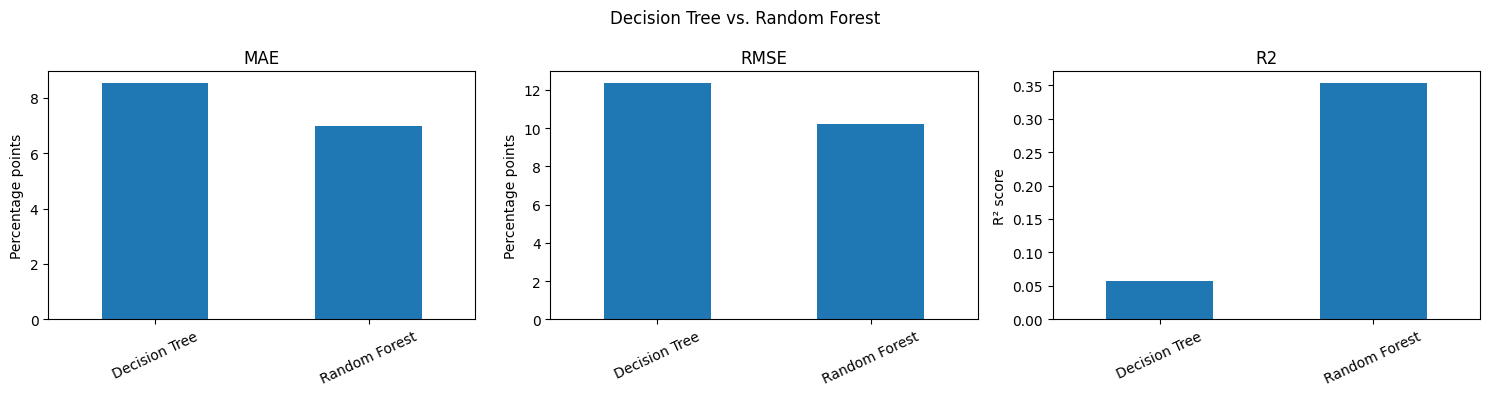


Evaluation complete. Downloading tables.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# CASTORS RESEARCH INITIATIVE
# RANDOM FOREST PERFORMANCE EVALUATION
#
# Metrics:
# 1. Mean Absolute Error (MAE)
# 2. Root Mean Squared Error (RMSE)
# 3. Cross-Validated R²
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# STEP 1: Upload existing Random Forest results
print("Upload CASTORS_Random_Forest_Validated_Results.csv")
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

# STEP 2: Identify columns
actual_col = "Observed_SNAP_Household_Share_Pct"
rf_col = "RF_Predicted_SNAP_Share_Pct"
tree_col = "CV_Predicted_SNAP_Share_Pct"
fold_col = "CV_Fold"

required = [actual_col, rf_col, tree_col, fold_col]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

if df[required].isna().any().any():
    raise ValueError("Required columns contain missing values.")

actual = df[actual_col].to_numpy()
rf_pred = df[rf_col].to_numpy()
tree_pred = df[tree_col].to_numpy()

# STEP 3: Calculate overall cross-validated metrics
# These are pooled out-of-fold predictions.

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred)
    }

results = pd.DataFrame({
    "Decision Tree": calculate_metrics(actual, tree_pred),
    "Random Forest": calculate_metrics(actual, rf_pred)
}).T

print("\nOVERALL CROSS-VALIDATED MODEL PERFORMANCE")
print(results.round(4).to_string())

# STEP 4: Evaluate each validation fold
fold_results = []

for fold, group in df.groupby(fold_col):

    metrics = calculate_metrics(
        group[actual_col],
        group[rf_col]
    )

    fold_results.append({
        "Fold": fold,
        "Number_of_Tracts": len(group),
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "R2": metrics["R2"]
    })

fold_table = pd.DataFrame(fold_results)

print("\nRANDOM FOREST PERFORMANCE BY VALIDATION FOLD")
print(fold_table.round(4).to_string(index=False))

# STEP 5: Compare overall performance visually
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):

    results[metric].plot(
        kind="bar",
        ax=ax,
        legend=False
    )

    ax.set_title(metric)
    ax.set_ylabel("Percentage points" if metric != "R2"
                  else "R² score")
    ax.tick_params(axis="x", rotation=25)

plt.suptitle("Decision Tree vs. Random Forest")
plt.tight_layout()
plt.show()

# STEP 6: Export results
results.to_csv(
    "CASTORS_Model_Performance_Final.csv"
)

fold_table.to_csv(
    "CASTORS_Random_Forest_CV_Metrics.csv",
    index=False
)

print("\nEvaluation complete. Downloading tables.")

files.download("CASTORS_Model_Performance_Final.csv")
files.download("CASTORS_Random_Forest_CV_Metrics.csv")


## Export for GIS

Join the CSV to 2020-based Census tract polygons with the 11-digit text `GEOID`. The `CV_Predicted` column is the suitable held-out estimate for exploratory mapping. Maps should include the measured outcome and uncertainty caveats. This model is **not** a validated priority, donation, or future-food-insecurity predictor.

In [ ]:
result = pd.concat([df[["GEOID", "Tract_Name"]].reset_index(drop=True), X.reset_index(drop=True)], axis=1)
result["Observed_SNAP_Household_Share_Pct"] = y.round(3)
result["CV_Predicted_SNAP_Share_Pct"] = np.round(oof, 3)
result["CV_Baseline_SNAP_Share_Pct"] = np.round(baseline, 3)
result["CV_Fold"] = fold
result["Full_Model_Fitted_SNAP_Share_Pct"] = np.round(final_tree.predict(X),3)
result.to_csv("CASTORS_Predictive_Tree_Validated_Results.csv", index=False)
files.download("CASTORS_Predictive_Tree_Validated_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Recommended research upgrade

For a stronger, contemporary and less temporally mismatched outcome, obtain **2024 ACS B22003** tract-level households receiving SNAP (and the matching total households), then replace the target accordingly. An even stronger target for food-recovery planning would be independently collected, privacy-protective **food-bank service demand or measured partnership capacity**, aggregated to tracts. Revalidate using spatial blocks or a separate period/county. Never describe SNAP program participation as a direct measure of food insecurity.